# Can we see food price spikes coming in Indonesian markets?

Monthly retail prices of three staples (medium rice, local sugar, vegetable oil) in about 220
traditional markets, 2020 to 2026, from the WFP / HDX dataset. The notebook walks through the
pipeline: clean and explore (step 2), add exchange rate and inflation (step 3), forecast 1 to 3
months ahead and flag spikes (step 4). The code lives in `prepare.py` and `model.py`; this
notebook calls it and shows the results.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import prepare as P
from common import FOODS, LABELS, FIG, REPORTS, DATA
pd.set_option("display.width", 140)

## 1. Raw data

In [2]:
raw = P.load_raw()
print(f"{len(raw):,} rows, {raw.market.nunique()} markets, {raw.commodity.nunique()} commodities, "
      f"{raw.date.min():%Y-%m} to {raw.date.max():%Y-%m}")
raw.head()

347,001 rows, 223 markets, 30 commodities, 2007-01 to 2026-11


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2007-01-15,NaN,NaN,National Average,974,NaN,NaN,cereals and tubers,Wheat flour,58,KG,actual,Retail,IDR,4328.26,0.48
1,2007-01-15,NaN,NaN,National Average,974,NaN,NaN,"meat, fish and eggs",Eggs,92,KG,actual,Retail,IDR,9150.74,1.00
2,2007-01-15,NaN,NaN,National Average,974,NaN,NaN,"meat, fish and eggs",Meat (beef),141,KG,actual,Retail,IDR,49165.11,5.40
3,2007-01-15,NaN,NaN,National Average,974,NaN,NaN,"meat, fish and eggs","Meat (chicken, broiler)",89,KG,actual,Retail,IDR,20122.80,2.21
4,2007-01-15,NaN,NaN,National Average,974,NaN,NaN,milk and dairy,Milk (condensed),95,385 G,actual,Retail,IDR,5804.29,0.64


In [3]:
raw.groupby("commodity").agg(rows=("price", "size"), markets=("market", "nunique"),
                             first=("date", "min"), last=("date", "max")).sort_values("rows", ascending=False).head(12)

,rows,markets,first,last
commodity,,,,
Eggs,17863,223,2007-01-15,2026-11-15
Oil (vegetable),17834,223,2007-01-15,2026-11-15
"Onions (shallot, medium)",17714,222,2016-07-15,2026-11-15
Garlic (medium),17714,222,2016-07-15,2026-11-15
Sugar (local),17697,222,2016-07-15,2026-11-15
Rice (medium quality),17486,220,2016-07-15,2026-11-15
Meat (chicken),17420,220,2016-07-15,2026-11-15
"Meat (beef, first quality)",16233,210,2016-07-15,2026-11-15
Rice,11797,215,2007-02-15,2024-05-15


Maize is not in the file, and wheat flour has only one national series that stops in 2020, so the
staples used are **medium rice, local sugar and vegetable oil** (all per kg, reported per market).
Every date is the 15th of a month: the data is already monthly. The monthly average below mostly
merges duplicates.

## 2. Clean and explore

In [4]:
m = P.staple_panel(raw)
p = P.complete_months(m)          # every month from first to last report, gaps become NaN
p = P.flag_outliers(p)
p = P.clean_series(p)
p[["food", "market", "province", "month", "price", "outlier", "price_clean", "imputed"]].dropna().sample(5, random_state=1)

,food,market,province,month,price,outlier,price_clean,imputed
45438,rice,Pasar Raya,SUMATERA BARAT,2021-03-01,13818.18,False,13818.18,False
36682,rice,Pasar Pagi (Kota Samarinda),KALIMANTAN TIMUR,2021-05-01,12750.00,False,12750.00,False
60829,sugar,Pasar Agro Politan,KALIMANTAN UTARA,2022-12-01,16000.00,False,16000.00,False
50592,sugar,Pasar Beringharjo,DAERAH ISTIMEWA YOGYAKARTA,2021-04-01,12750.00,False,12750.00,False
4642,oil,Pasar Warung Jambu 2,JAWA BARAT,2023-11-01,18500.00,False,18500.00,False


### Gaps

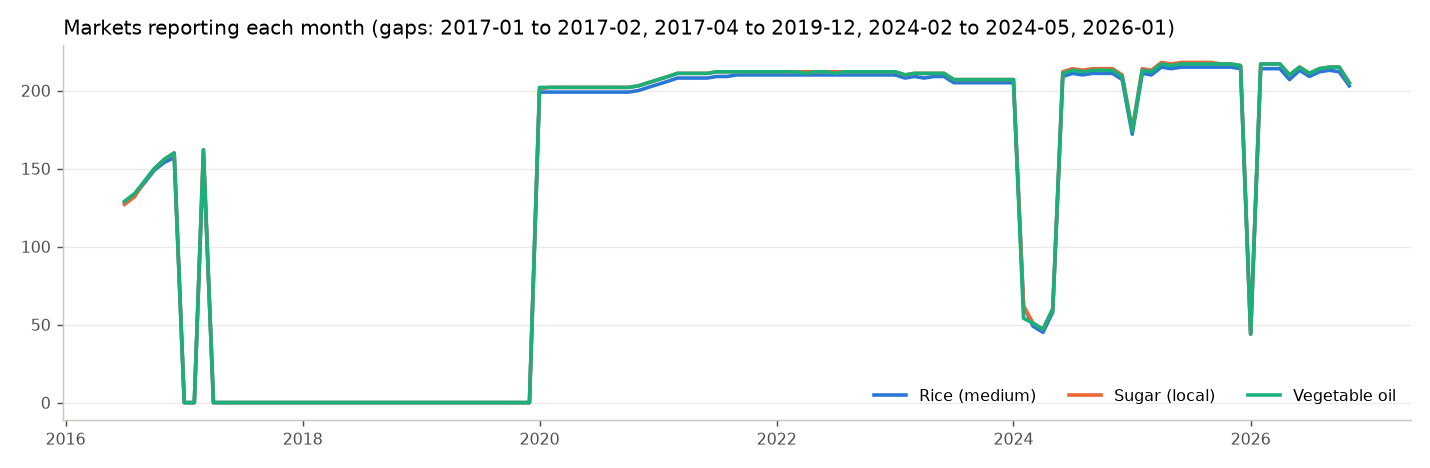

In [5]:
P.fig_coverage(p)
Image(FIG / "coverage.png")

In [6]:
last = p.month.max()
gaps = P.gap_report(p, last)
gaps.groupby("food")[["missing", "longest_gap", "outliers"]].agg(["sum", "max"])

missing     longest_gap     outliers    
          sum max         sum max      sum max
food                                          
oil       903  24         691  24       40   3
rice      906  24         693  24        1   1
sugar     904  24         694  24       20   2

Three holes: almost no market data from 2017-04 to 2019-12, only about 50 markets from 2024-02 to
2024-05, and about 45 in 2026-01. Modelling starts in 2020-01. Gaps of up to 2 months are filled
log-linearly; longer gaps stay empty (SARIMA's Kalman filter and LightGBM both handle missing values).

### Outliers

Each market is compared with the median of all markets in the same month, then with its own
5-month rolling median of that gap. A point is an outlier when it is more than 5 robust standard
deviations **and** more than 15% away. Comparing with all markets first matters: a first version
without it flagged the 2022 cooking-oil crisis, which was real and hit every market.

food
oil      40
rice      4
sugar    20


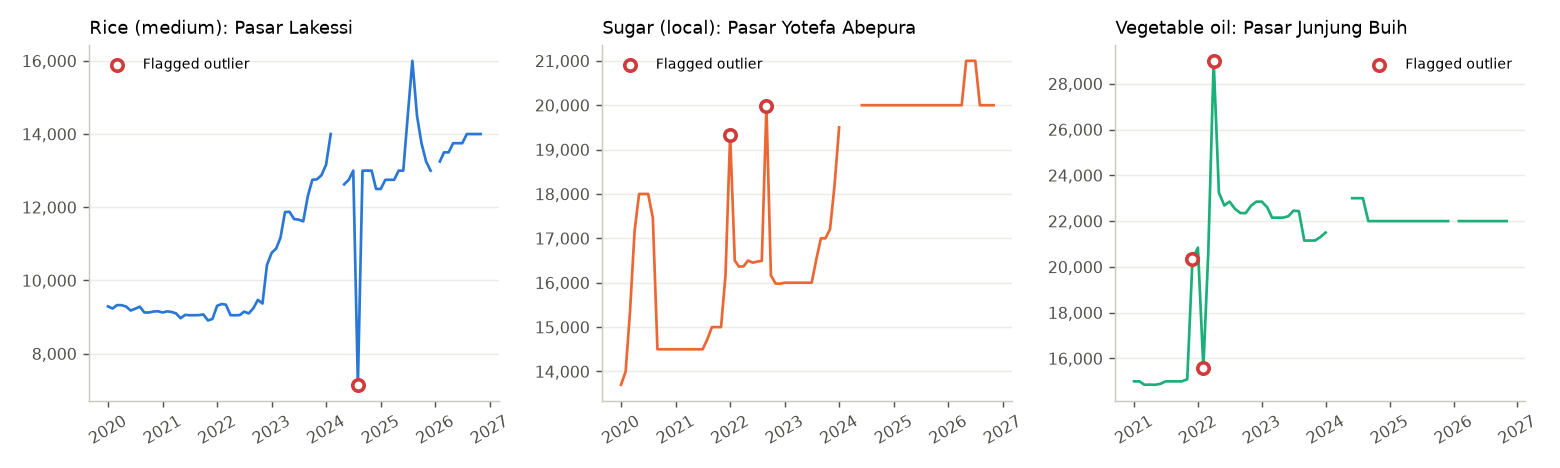

In [7]:
out = p[p.outlier]
print(out.groupby("food").size().to_string())
P.fig_outliers(p, out[["food", "market_id", "market", "province", "month", "price", "z"]])
Image(FIG / "outliers_examples.png")

### Prices over time, per market

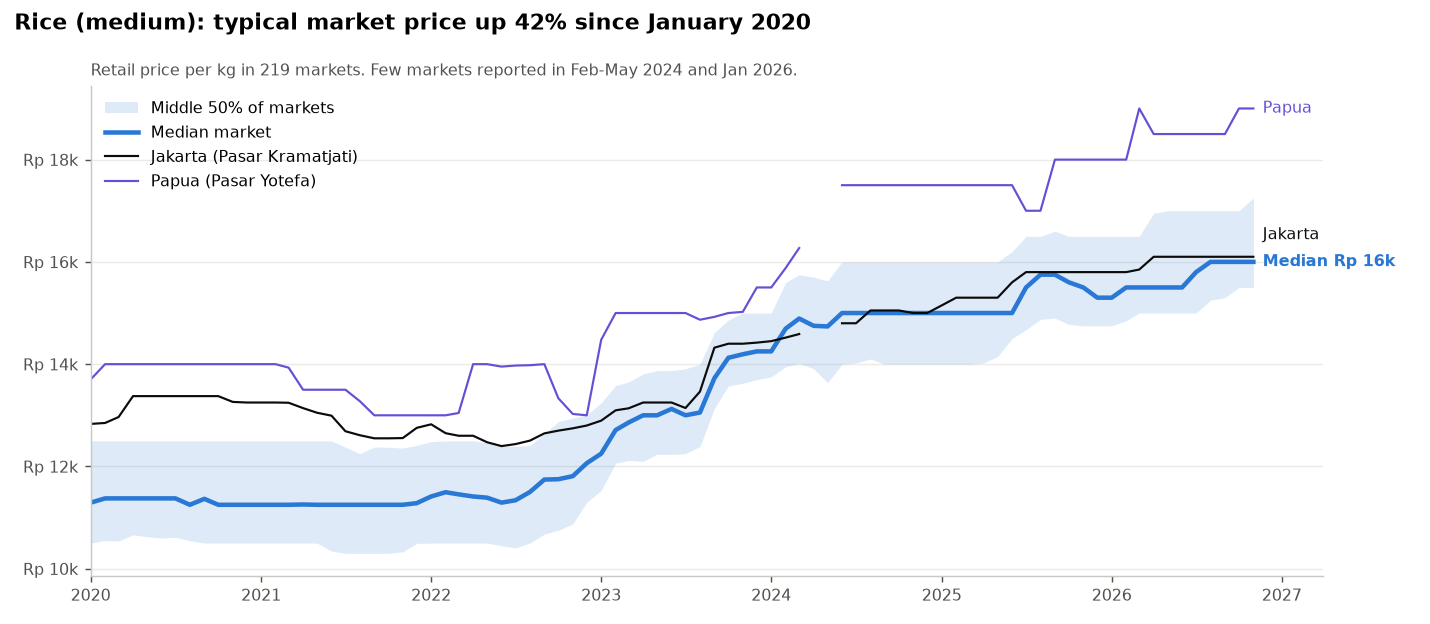

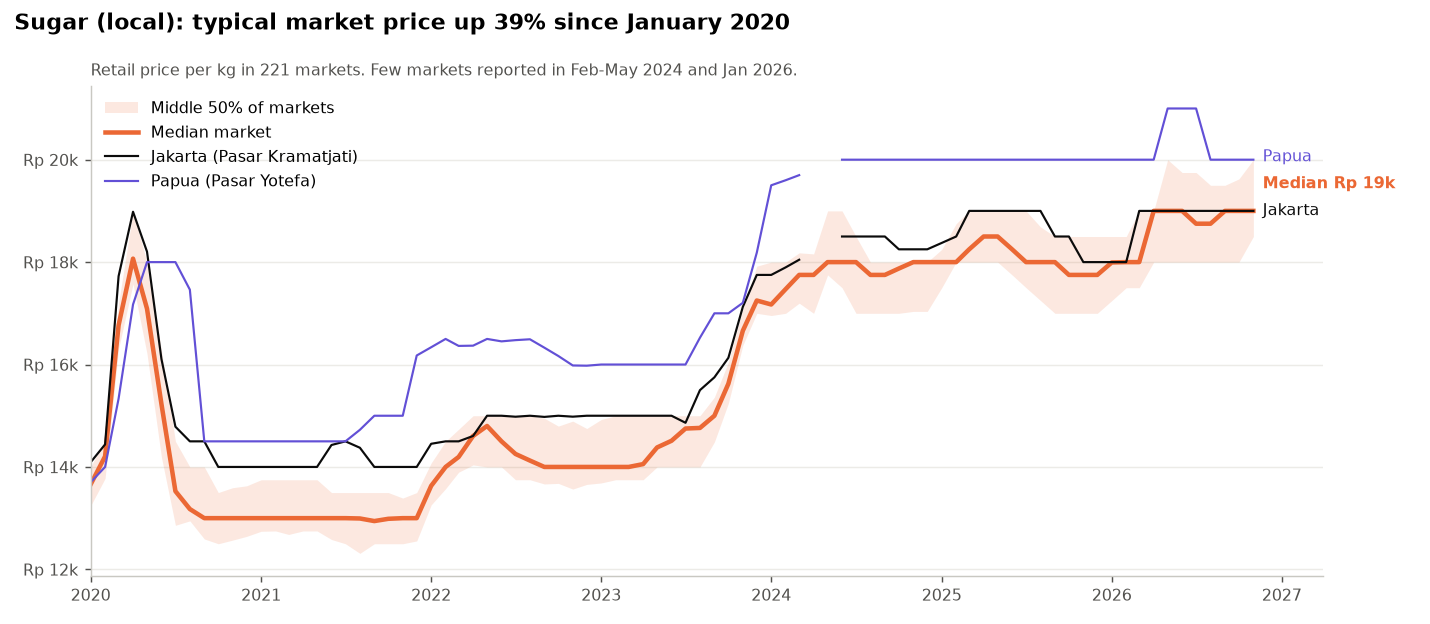

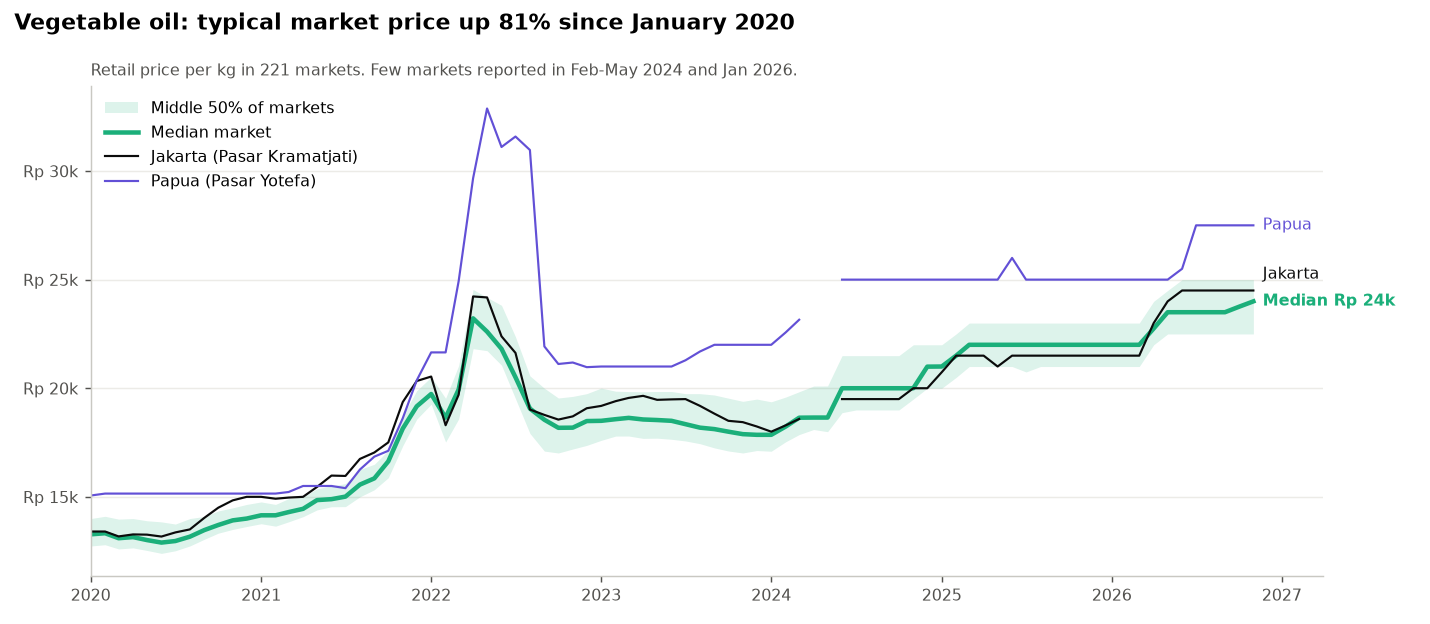

In [8]:
for food in FOODS:
    P.fig_prices(p, food)
    display(Image(FIG / f"prices_{food}.png"))

Oil shows the 2022 crisis (export ban, price caps). From mid-2024 the source switches to
reported ('actual') prices, and many series become step-shaped: the same price for months, then
a jump. That shape matters for forecasting below.

## 3. Context: exchange rate and inflation

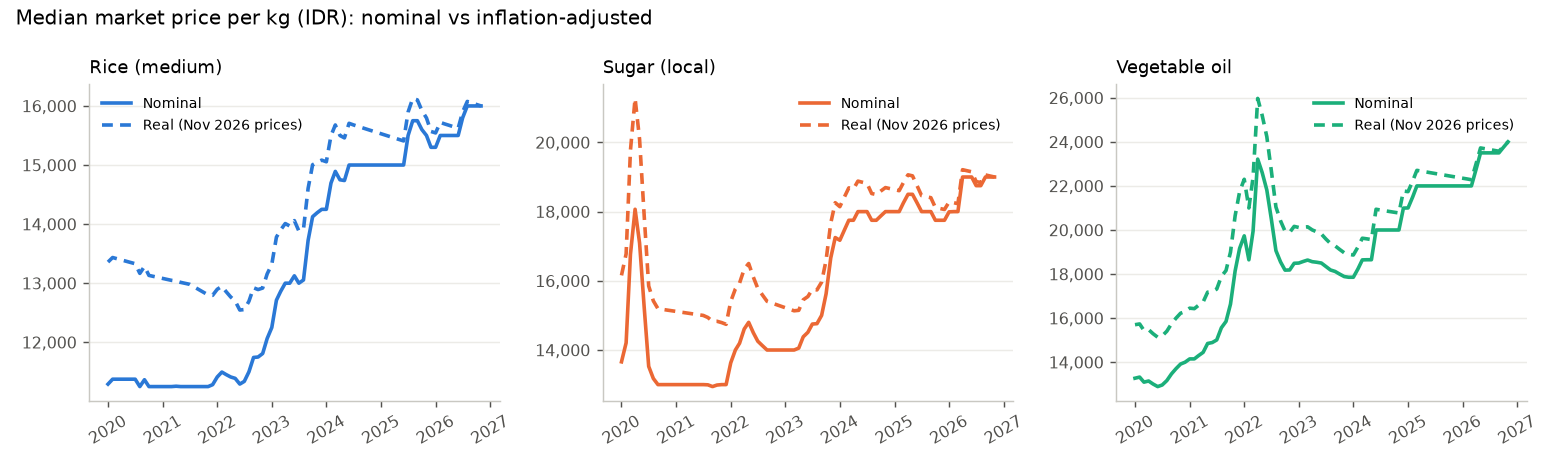

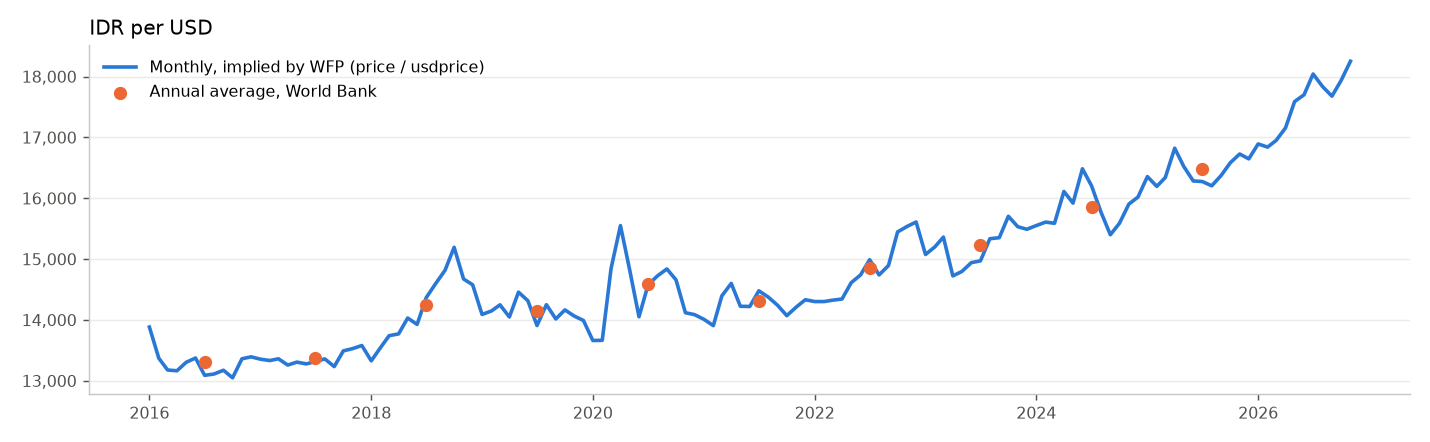

,cpi,idr_usd,inflation_pct,idr_usd_wb
month,,,,
2026-09-01,179.982551,17676.767677,NaN,NaN
2026-10-01,180.267038,17932.489451,NaN,NaN
2026-11-01,180.551973,18250.688705,NaN,NaN


In [9]:
ctx, wb = P.context(raw, p.month)
P.fig_real(p, ctx); P.fig_fx(ctx)
display(Image(FIG / "nominal_vs_real.png")); display(Image(FIG / "fx.png"))
ctx.dropna(subset=["idr_usd"]).tail(3)

The monthly IDR/USD rate comes from the dataset itself (WFP converts every price: `price / usdprice`
is the same rate for all rows of a month, spread under 20 IDR). CPI and annual inflation come from
the World Bank API. In real terms rice and sugar are up much less than in nominal terms; oil is up
the most.

## 4. Forecast and spike alert

`model.py` (about 12 minutes on 8 cores) runs a rolling-origin backtest: at 22 origin months from
2021-03 to 2026-08 each model sees only the data up to that month and forecasts 1, 2 and 3 months
ahead for every market. Models:

- **Naive**: next months equal this month.
- **SARIMA(1,1,1)(1,0,0,12)** on log price, one model per market.
- **LightGBM**, one global model per food and horizon, predicting the log change from lags of the
  market, its province and the national median, exchange rate changes, last year's inflation and
  the calendar month.

**Spike alert**: the forecast is more than 15% above the trailing 12-month median price of that market.

In [10]:
mt = pd.read_csv(REPORTS / "backtest_metrics.csv")
t = mt.pivot_table(index=["food", "h"], columns="model", values="mape")[["naive", "sarima", "lgbm"]] * 100
t.round(2)

model    naive  sarima  lgbm
food  h                     
oil   1   2.42    2.76  2.85
      2   4.19    4.75  5.34
      3   5.15    5.80  6.98
rice  1   0.91    1.12  0.95
      2   1.69    1.93  1.98
      3   2.41    2.73  3.03
sugar 1   1.49    1.79  1.71
      2   2.53    2.80  3.06
      3   3.21    3.47  4.62

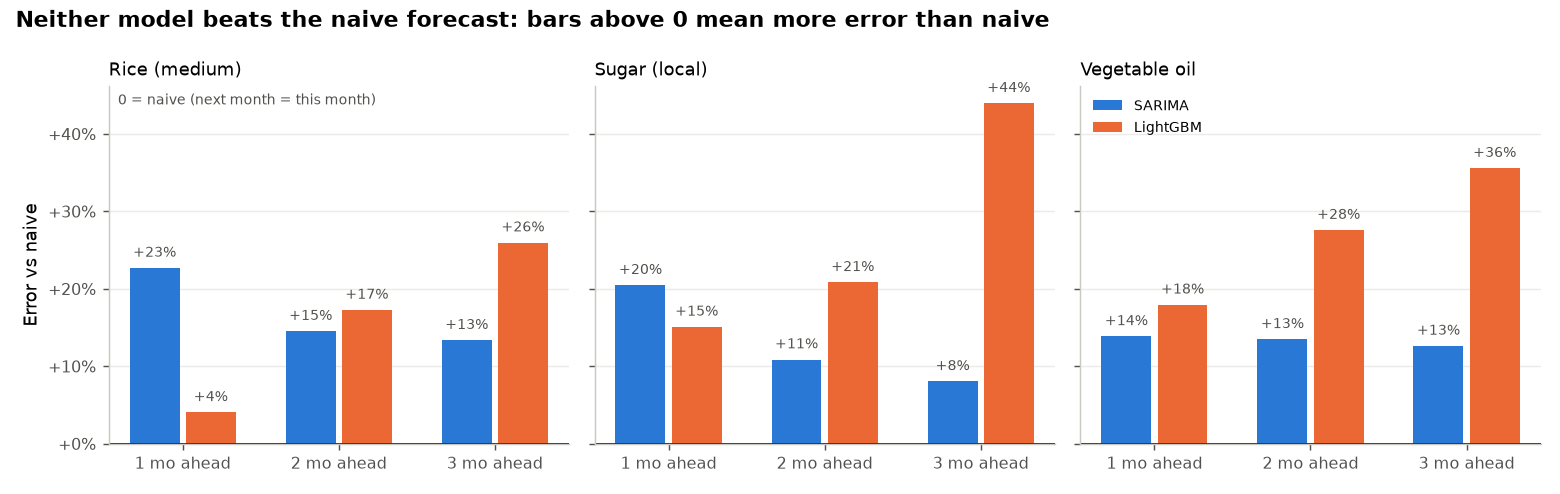

In [11]:
Image(FIG / 'backtest_mape.png')

In [12]:
bt = pd.read_parquet(DATA / "backtest.parquet")
naive = bt[bt.model == "naive"]
flat = ((naive.actual / naive.yhat - 1).abs() < 0.001).groupby([naive.food, naive.h]).mean().unstack()
print("Share of forecasts where the price did not change at all:")
flat.round(2)

Share of forecasts where the price did not change at all:


h,1,2,3
food,,,
oil,0.43,0.33,0.27
rice,0.64,0.51,0.42
sugar,0.53,0.41,0.33


**Point forecasts: naive wins.** Over all 22 origins neither SARIMA nor LightGBM beats the naive
forecast at any horizon (their errors are 4% to 44% higher). Averages of naive and a model did not
beat it either. The reason is in the table above: the price did not change at all in 43-64% of the
one-month cases. Prices move in steps, so a model that predicts a small drift every month loses on
every flat month. Error grows with the horizon, from about 1% (rice, 1 month) to 5% (oil, 3 months).

In [13]:
al = pd.read_csv(REPORTS / "backtest_alerts.csv")
al.pivot_table(index=["food", "h"], columns="model", values=["precision", "recall"]).round(2)

precision              recall             
model        lgbm naive sarima   lgbm naive sarima
food  h                                           
oil   1      0.70  0.85   0.80   0.81  0.76   0.75
      2      0.64  0.73   0.67   0.69  0.58   0.58
      3      0.59  0.75   0.70   0.70  0.52   0.53
rice  1      0.84  0.91   0.74   0.75  0.65   0.74
      2      0.60  0.81   0.65   0.55  0.41   0.53
      3      0.51  0.80   0.59   0.50  0.31   0.41
sugar 1      0.85  0.90   0.83   0.76  0.73   0.74
      2      0.24  0.79   0.61   0.11  0.28   0.26
      3      0.17  0.74   0.57   0.02  0.23   0.23

**Spike alerts: the models add something.** Naive can only flag a market whose price is already 15%
above its trend. The models also catch some spikes before they show: at 1 month LightGBM finds
81% of the oil spikes (naive 76%) and 75% of the rice spikes (naive 65%); at 3 months 70% of the oil
spikes (naive 52%). The cost is precision: more false alarms (oil, 1 month: 70% of LightGBM alerts
were real, 85% for naive). For sugar at 2-3 months LightGBM almost never alerts (recall 11% and 2%).

## 5. Current alerts

In [14]:
fc = pd.read_parquet(DATA / "forecasts.parquet")
cur = fc[fc.best & fc.alert]
print(f"Forecast from {fc.origin.max():%Y-%m}; best model per food: "
      + ", ".join(f"{LABELS[f]} = {g.model.iat[0]}" for f, g in fc[fc.best].groupby("food")))
(cur.assign(above_trend=cur.vs_trend.map("{:+.0%}".format))
    [["food", "market", "province", "target", "yhat", "trend", "above_trend"]]
    .sort_values(["food", "market", "target"]).round(0))

Forecast from 2026-11; best model per food: Vegetable oil = naive, Rice (medium) = naive, Sugar (local) = naive


/tmp/ipykernel_14144/2363694654.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .sort_values(["food", "market", "target"]).round(0))


,food,market,province,target,yhat,trend,above_trend
5004,oil,Pasar Baru (regional Mamuju) (Kab. Mamuju),SULAWESI BARAT,2026-12-01,28000.0,24000.0,+17%
5007,oil,Pasar Baru (regional Mamuju) (Kab. Mamuju),SULAWESI BARAT,2027-01-01,28000.0,24000.0,+17%
5010,oil,Pasar Baru (regional Mamuju) (Kab. Mamuju),SULAWESI BARAT,2027-02-01,28000.0,24000.0,+17%
4707,oil,Pasar Gotong Royong,MALUKU,2026-12-01,26500.0,23000.0,+15%
4710,oil,Pasar Gotong Royong,MALUKU,2027-01-01,26500.0,23000.0,+15%
4713,oil,Pasar Gotong Royong,MALUKU,2027-02-01,26500.0,23000.0,+15%
4851,oil,Pasar Lama Sentani,PAPUA,2026-12-01,30000.0,26000.0,+15%
4854,oil,Pasar Lama Sentani,PAPUA,2027-01-01,30000.0,26000.0,+15%
4857,oil,Pasar Lama Sentani,PAPUA,2027-02-01,30000.0,26000.0,+15%
855,rice,Pasar Antasari,KALIMANTAN SELATAN,2026-12-01,20500.0,17550.0,+17%


## Conclusions and limits

- Monthly market prices of rice, sugar and oil in Indonesia are sticky: for a point forecast,
  "same as this month" is the benchmark to beat, and SARIMA and LightGBM did not beat it here.
- For spike alerts a model is useful at 1-3 months for oil and rice, with more false alarms.
  The app uses the model with the lowest backtest error (naive) by default and lets the user
  switch to SARIMA or LightGBM.
- Limits: three data gaps (2017-2019, early 2024, January 2026); a source change in mid-2024
  (aggregated to reported prices, more step-shaped series); 16% of SARIMA fits failed and fell
  back to naive; CPI after 2025 is extrapolated; no weather, policy or global price data.
- Next steps: add global palm oil and rice prices and rainfall, model the probability of a spike
  directly (classification), and tune the alert limit per food.